
![](img/logoitqv1.jpg)

#  Neurona MCCulloch y Pitts

![](img/python_logo.png)



*Alysson Guaman*

**Repositorio:** [Github](https://github.com/a12lj/machine-learning.git)

# Caso Práctico: Neurona de McCulloch y Pitts

2. Aplicando la MPNeuronaa un caso pråctico real

# Conjunto de datos

Esta es una copia de los conjuntos de datos de UCI ML Breast Cancer Winconsin https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic
Descipci6n de la muestra
Las caracteristicas de netrada se calculan a partir de una imagen digitaizada de un aspirado de aguja fina (FNA) de una masa mamaria. Describen las caracteristicas de los
npucles celulares presentes en la imagén.
El plano de separaciön descrito anteriormente se obtuvo utilizando el m•petodo de årbol de multiples superficies (MSM-T) "COnstrucci6n de un årbol de decisi6n mediante
programaciön lineal).
El programa lineal utilizado para obtener el plano de separaci6n en el espacio tridimensional es el que describe en [K.P Bennet y O. L Mangasarian]

# Lectura de datos

In [3]:
from sklearn.datasets import load_breast_cancer
cancer_mama = load_breast_cancer()
#separamos los datos de entrada y los datos de salida
X=cancer_mama.data
Y=cancer_mama.target


In [4]:
dir(cancer_mama)

['DESCR',
 'data',
 'data_module',
 'feature_names',
 'filename',
 'frame',
 'target',
 'target_names']

In [5]:
print(X)

[[1.799e+01 1.038e+01 1.228e+02 ... 2.654e-01 4.601e-01 1.189e-01]
 [2.057e+01 1.777e+01 1.329e+02 ... 1.860e-01 2.750e-01 8.902e-02]
 [1.969e+01 2.125e+01 1.300e+02 ... 2.430e-01 3.613e-01 8.758e-02]
 ...
 [1.660e+01 2.808e+01 1.083e+02 ... 1.418e-01 2.218e-01 7.820e-02]
 [2.060e+01 2.933e+01 1.401e+02 ... 2.650e-01 4.087e-01 1.240e-01]
 [7.760e+00 2.454e+01 4.792e+01 ... 0.000e+00 2.871e-01 7.039e-02]]


In [6]:
# Visualizaci6n del conjunto de datos

In [7]:
import pandas as pd
df=pd.DataFrame(X, columns=cancer_mama.feature_names)
df

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [8]:
print(Y)

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 1 0 0 0 0 0 0 0 0 1 0 1 1 1 1 1 0 0 1 0 0 1 1 1 1 0 1 0 0 1 1 1 1 0 1 0 0
 1 0 1 0 0 1 1 1 0 0 1 0 0 0 1 1 1 0 1 1 0 0 1 1 1 0 0 1 1 1 1 0 1 1 0 1 1
 1 1 1 1 1 1 0 0 0 1 0 0 1 1 1 0 0 1 0 1 0 0 1 0 0 1 1 0 1 1 0 1 1 1 1 0 1
 1 1 1 1 1 1 1 1 0 1 1 1 1 0 0 1 0 1 1 0 0 1 1 0 0 1 1 1 1 0 1 1 0 0 0 1 0
 1 0 1 1 1 0 1 1 0 0 1 0 0 0 0 1 0 0 0 1 0 1 0 1 1 0 1 0 0 0 0 1 1 0 0 1 1
 1 0 1 1 1 1 1 0 0 1 1 0 1 1 0 0 1 0 1 1 1 1 0 1 1 1 1 1 0 1 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 1 1 1 1 1 1 0 1 0 1 1 0 1 1 0 1 0 0 1 1 1 1 1 1 1 1 1 1 1 1
 1 0 1 1 0 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 0 1 0 1 1 1 1 0 0 0 1 1
 1 1 0 1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 0 0 0 1 1 1 1 1 1 1 1 1 1 1 0 0 1 0 0
 0 1 0 0 1 1 1 1 1 0 1 1 1 1 1 0 1 1 1 0 1 1 0 0 1 1 1 1 1 1 0 1 1 1 1 1 1
 1 0 1 1 1 1 1 0 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 0 1 0 0 1 0 1 1 1 1 1 0 1 1
 0 1 0 1 1 0 1 0 1 1 1 1 1 1 1 1 0 0 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 0 1
 1 1 1 1 1 1 0 1 0 1 1 0 

# División del conjunto de datos

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(df, Y, stratify= Y)
print("tamaño de entrenamiento", len(X_train))
print("tamaño de pruebas", len(X_test))

tamaño de entrenamiento 426
tamaño de pruebas 143


# Implementación de una MP Neurona más avanzada

In [10]:
# importamos la biblioteca de numpy
import numpy as np
from sklearn.metrics import accuracy_score

class MpNeurona:
    # creamos nuestro constructor
    def __init__(self):
        self.threshold=None

    # Creamos una función par el modelo
    def model(self, x):
        #input: [1,0,1,0][x1,x2,...xn]
        z=sum(x)
        return (z >= self.threshold)

    #Creamos la predicción
    def predict(self, X):
        # input:[[1,0,1,0][1,0,1,1]]
        Y=[]
        for x in X:
            result=self.model(x)
            Y.append(result)
        return np.array(Y)

    # función de entrenamiento para el threshold
    def fit(self, X, Y):
        accuracy={}
        #Seleccionamos un threshold entre el # de caracteristicas de entrada
        for th in range(X.shape[1]+1):
            self.threshold = th
            Y_pred = self.predict(X)
            accuracy[th]=accuracy_score(Y_pred, Y)
        #Seleccionamos el threshold que mejores resultado proporciona
        self.threshold = max(accuracy, key=accuracy.get)

Los datos de entreeda siguen teniendo porblemas debido a que nuestro conjunto de datos las caracteristicas de entreda reciben valores continuos, sin embargo, la neurona MP
solo procesa caracteristicas de netrada con valores binarios

[0, 0, 1, 1, 1, 0, 0]
Categories (2, int64): [0 < 1]


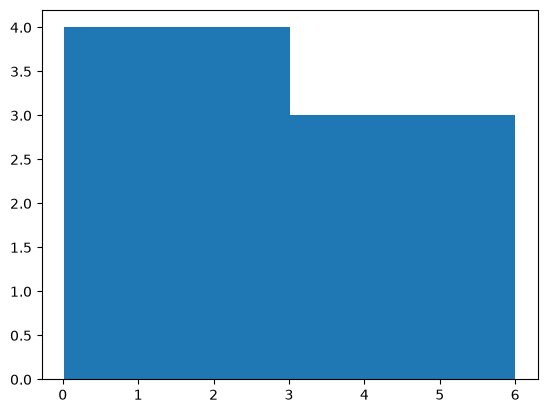

In [11]:
# Para transformar un valor a binario
import matplotlib.pyplot as plt
print(pd.cut([0.04,0.3,4,5,6,0.02,0.6], bins=2, labels=[0,1]))

plt.hist([0.04,0.3,4,5,6,0.02,0.6], bins=2)
plt.show()

In [12]:
#Trasformarmamos Las caracteristicas de entrada a un valor binario
X_train_bin = X_train.apply(pd.cut, bins=2, labels=[1,0])
X_test_bin =  X_test.apply(pd.cut, bins=2, labels=[1,0])

X_train_bin

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
394,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
174,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
368,0,1,0,0,1,1,1,1,1,1,...,0,1,0,0,1,1,1,0,1,1
156,0,1,0,1,1,1,1,0,1,1,...,1,1,1,1,1,1,1,0,1,1
381,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,0,1,1,1,1,1
445,1,0,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
229,1,1,1,1,1,1,1,1,0,1,...,1,1,1,1,0,1,0,0,1,1
328,1,1,1,1,0,1,1,1,1,1,...,1,1,1,1,0,1,1,0,1,1


In [13]:
# instaciamos eL modeLo mP
np_neurona = MpNeurona()
#Encontramos eL threshold optimo
np_neurona.fit(X_train_bin.to_numpy(), y_train)
# threshold optimo se[eccionado
np_neurona.threshold

27

In [14]:
# Real izamos La predicciön par alos datos de prueba
Y_pred = np_neurona.predict(X_test_bin.to_numpy())

In [15]:
Y_pred

array([False, False, False,  True, False, False,  True,  True, False,
       False,  True,  True, False,  True, False, False,  True,  True,
        True,  True, False,  True,  True,  True,  True, False,  True,
        True, False,  True, False,  True,  True,  True,  True, False,
        True, False,  True,  True,  True, False,  True,  True, False,
        True, False,  True, False,  True,  True,  True,  True,  True,
       False, False,  True,  True,  True, False,  True, False,  True,
       False,  True,  True, False,  True, False,  True, False, False,
       False, False, False,  True,  True,  True,  True,  True, False,
       False,  True, False, False,  True, False, False,  True,  True,
        True, False,  True,  True,  True,  True,  True, False, False,
        True, False,  True,  True,  True,  True, False,  True, False,
       False,  True, False,  True,  True,  True, False, False,  True,
       False,  True, False,  True,  True,  True,  True, False,  True,
       False,  True,

In [16]:
#Calculamos la exactiud de nuestra predicción
accuracy_score(y_test, Y_pred)

0.8741258741258742

In [17]:
# Mostrar las columnas del conjunto de datos
print(df.columns.tolist())

# Mostrar las dimensiones del DataFrame
print("Filas y columnas:", df.shape)

# Mostrar los tipos de datos
print(df.dtypes)

# Mostrar las primeras filas
display(df.head())

# Revisar si existen valores nulos
print(df.isnull().sum())

['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']
Filas y columnas: (569, 30)
mean radius                float64
mean texture               float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        float64
mean symmetry              float64
mean fractal dimension     float64
radius error               float64
texture err

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64


In [18]:
# Mostrar todos los nombres de las columnas
print(df.columns.tolist())

['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']


In [19]:
# Buscar columnas relacionadas con el diagnóstico
print([
    columna for columna in df.columns
    if "diagnosis" in columna.lower()
    or "target" in columna.lower()
])

[]


In [20]:
# Mostrar las últimas columnas y sus valores
display(df.iloc[:, -5:].head())

# Revisar las dimensiones del DataFrame
print("Dimensiones:", df.shape)

,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,0.6656,0.7119,0.2654,0.4601,0.11890
1,0.1866,0.2416,0.1860,0.2750,0.08902
2,0.4245,0.4504,0.2430,0.3613,0.08758
3,0.8663,0.6869,0.2575,0.6638,0.17300
4,0.2050,0.4000,0.1625,0.2364,0.07678


Dimensiones: (569, 30)


In [21]:
# Mostrar las primeras filas de los datos originales
display(df.head())

# Revisar si existen otras variables guardadas
print("Variables disponibles:", list(globals().keys()))

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Variables disponibles: ['__name__', '__doc__', '__package__', '__loader__', '__spec__', '__builtin__', '__builtins__', '_ih', '_oh', '_dh', 'In', 'Out', 'get_ipython', 'exit', 'quit', 'open', '_', '__', '___', '__session__', 'json', 'sys', '__import__', 'islice', 'collections', 'NamespaceMagics', '_jupyterlab_variableinspector_nms', '_jupyterlab_variableinspector_Jupyter', '_jupyterlab_variableinspector_maxitems', '__np', '__pd', '__pyspark', '__tf', '__K', '__torch', '__ipywidgets', '__xr', '_attempt_import', '_check_imported', '_jupyterlab_variableinspector_changesettings', '_jupyterlab_variableinspector_getsizeof', '_jupyterlab_variableinspector_getshapeof', '_jupyterlab_variableinspector_getcontentof', '_jupyterlab_variableinspector_is_matrix', '_jupyterlab_variableinspector_is_widget', '_jupyterlab_variableinspector_dict_list', '_jupyterlab_variableinspector_getmatrixcontent', '_jupyterlab_variableinspector_displaywidget', '_jupyterlab_variableinspector_default', '_jupyterlab_vari

In [22]:
# Revisar si el conjunto de datos original está disponible
print("¿Existe load_breast_cancer?:", "load_breast_cancer" in globals())
print("¿Existe cancer_mama?:", "cancer_mama" in globals())
print("¿Existe X?:", "X" in globals())
print("¿Existe y?:", "y" in globals())

¿Existe load_breast_cancer?: True
¿Existe cancer_mama?: True
¿Existe X?: True
¿Existe y?: False


In [23]:
# Recuperar el conjunto de datos original
datos_cancer = load_breast_cancer()

# Mostrar los nombres de las categorías
print("Categorías:", datos_cancer.target_names)

# Mostrar la cantidad de registros por categoría
import pandas as pd

print(pd.Series(datos_cancer.target).value_counts())

Categorías: ['malignant' 'benign']
1    357
0    212
Name: count, dtype: int64


In [24]:
# Agregar el diagnóstico al DataFrame
df_completo = df.copy()

# Recuperar el diagnóstico original
df_completo["diagnostico"] = datos_cancer.target

# Convertir los valores a nombres
df_completo["resultado"] = df_completo["diagnostico"].map({
    0: "Maligno",
    1: "Benigno"
})

# Mostrar las primeras filas
display(df_completo.head())

# Verificar las dimensiones
print("Dimensiones:", df_completo.shape)

# Contar los diagnósticos
print(df_completo["resultado"].value_counts())

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnostico,resultado
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,Maligno
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,Maligno
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,Maligno
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,Maligno
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,Maligno


Dimensiones: (569, 32)
resultado
Benigno    357
Maligno    212
Name: count, dtype: int64


In [25]:
# Calcular correlación con el diagnóstico
correlaciones = df_completo.drop(
    columns=["resultado"]
).corr()["diagnostico"]

# Eliminar el diagnóstico de la comparación
correlaciones = correlaciones.drop("diagnostico")

# Ordenar por la magnitud de correlación
importancia = correlaciones.abs().sort_values(
    ascending=False
)

# Mostrar los 10 parámetros más destacados
print("Los 10 parámetros más relacionados con el diagnóstico:")
display(importancia.head(10))

Los 10 parámetros más relacionados con el diagnóstico:


worst concave points    0.793566
worst perimeter         0.782914
mean concave points     0.776614
worst radius            0.776454
mean perimeter          0.742636
worst area              0.733825
mean radius             0.730029
mean area               0.708984
mean concavity          0.696360
worst concavity         0.659610
Name: diagnostico, dtype: float64

In [26]:

# Importar las herramientas necesarias
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Separar las características y el diagnóstico
X = df_completo[df.columns]
y = df_completo["diagnostico"]

# Dividir los datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Crear el modelo y estandarizar los datos
modelo = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

# Entrenar el modelo
modelo.fit(X_train, y_train)

# Realizar predicciones con los datos de prueba
y_pred = modelo.predict(X_test)

# Evaluar los resultados
print("Exactitud:", accuracy_score(y_test, y_pred))

print("\nReporte de clasificación:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Maligno", "Benigno"]
    )
)

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_pred))


Exactitud: 0.9824561403508771

Reporte de clasificación:
              precision    recall  f1-score   support

     Maligno       0.98      0.98      0.98        42
     Benigno       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


Matriz de confusión:
[[41  1]
 [ 1 71]]


In [27]:
import joblib

# Guardar el modelo entrenado
joblib.dump(modelo, "modelo_cancer.pkl")

# Guardar los nombres y el orden de las características
joblib.dump(df.columns.tolist(), "columnas_modelo.pkl")

print("Modelo y características guardados correctamente.")

Modelo y características guardados correctamente.


In [28]:
import os

# Mostrar la ubicación real del notebook
print("Carpeta actual:", os.getcwd())

# Buscar los archivos del modelo
for carpeta, subcarpetas, archivos in os.walk(os.getcwd()):
    for archivo in archivos:
        if archivo in ["modelo_cancer.pkl", "columnas_modelo.pkl"]:
            print(os.path.join(carpeta, archivo))

Carpeta actual: C:\Users\ESTUDIANTE\Desktop\Machine
C:\Users\ESTUDIANTE\Desktop\Machine\columnas_modelo.pkl
C:\Users\ESTUDIANTE\Desktop\Machine\modelo_cancer.pkl


In [29]:
import os
import joblib

# Crear la carpeta de la API si no existe
carpeta_api = os.path.join(os.getcwd(), "api_cancer")
os.makedirs(carpeta_api, exist_ok=True)

# Guardar el modelo dentro de la carpeta de la API
joblib.dump(
    modelo,
    os.path.join(carpeta_api, "modelo_cancer.pkl")
)

# Guardar los nombres de las características
joblib.dump(
    df.columns.tolist(),
    os.path.join(carpeta_api, "columnas_modelo.pkl")
)

# Mostrar los archivos guardados
print("Archivos de la API:")
print(os.listdir(carpeta_api))

Archivos de la API:
['.ipynb_checkpoints', 'api.py', 'columnas_modelo.pkl', 'modelo_cancer.pkl']


In [30]:
import os

# Comprobar los archivos del modelo
for archivo in ["modelo_cancer.pkl", "columnas_modelo.pkl"]:
    ruta = os.path.join(os.getcwd(), archivo)
    print(archivo, "->", os.path.exists(ruta))

modelo_cancer.pkl -> True
columnas_modelo.pkl -> True


In [31]:

# Mostrar los primeros 10 registros con sus diagnósticos reales
display(df_completo[["resultado"]].head(10))


,resultado
0,Maligno
1,Maligno
2,Maligno
3,Maligno
4,Maligno
5,Maligno
6,Maligno
7,Maligno
8,Maligno
9,Maligno


In [32]:

# Mostrar las características y el diagnóstico real
display(df_completo.head(10))


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnostico,resultado
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,Maligno
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,Maligno
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,Maligno
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,Maligno
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,Maligno
5,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,0.2087,0.07613,...,103.40,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440,0,Maligno
6,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,0.1794,0.05742,...,153.20,1606.0,0.1442,0.2576,0.3784,0.1932,0.3063,0.08368,0,Maligno
7,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,0.2196,0.07451,...,110.60,897.0,0.1654,0.3682,0.2678,0.1556,0.3196,0.11510,0,Maligno
8,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,0.2350,0.07389,...,106.20,739.3,0.1703,0.5401,0.5390,0.2060,0.4378,0.10720,0,Maligno
9,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,0.2030,0.08243,...,97.65,711.4,0.1853,1.0580,1.1050,0.2210,0.4366,0.20750,0,Maligno


In [33]:

import pandas as pd
from sklearn.metrics import accuracy_score

# Comparar los diagnósticos reales con las predicciones
comparacion = pd.DataFrame({
    "Diagnostico_real": y_test,
    "Diagnostico_predicho": y_pred
})

# Indicar si la predicción fue correcta
comparacion["Correcto"] = (
    comparacion["Diagnostico_real"] ==
    comparacion["Diagnostico_predicho"]
)

# Mostrar los primeros 15 resultados
display(comparacion.head(15))

# Calcular el porcentaje de aciertos
exactitud = accuracy_score(y_test, y_pred)

print(f"Exactitud del modelo: {exactitud * 100:.2f}%")
print("Predicciones correctas:", comparacion["Correcto"].sum())
print("Predicciones incorrectas:", (~comparacion["Correcto"]).sum())


,Diagnostico_real,Diagnostico_predicho,Correcto
256,0,0,True
428,1,1,True
501,0,0,True
363,1,1,True
564,0,0,True
464,1,1,True
358,1,1,True
343,0,0,True
516,0,0,True
567,0,0,True


Exactitud del modelo: 98.25%
Predicciones correctas: 112
Predicciones incorrectas: 2


In [34]:

# Mostrar la correspondencia entre los valores y los diagnósticos
display(
    df_completo[["diagnostico", "resultado"]]
    .drop_duplicates()
    .sort_values("diagnostico")
)


,diagnostico,resultado
0,0,Maligno
19,1,Benigno
